In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import datetime
from scipy.signal import detrend, decimate, correlate,correlation_lags
from obspy.signal.filter import bandpass, highpass
from tqdm import tqdm

## Converting to nc

In [ ]:
import os, glob

# Directory containing the .txt files
directory = '../data/rob_acc/2024*.txt'

# List to hold dataframes
dfs = []
files = glob.glob(directory)
files.sort()

In [ ]:

# Loop through all files in the directory
for filename in files:
    file_path = os.path.join(filename)
    df = pd.read_csv(file_path, delimiter='\t', index_col='Time [sec]', decimal=',',engine='python')  # Adjust delimiter if necessary
    dfs.append(df)

# Concatenate all dataframes
concatenated_df = pd.concat(dfs, ignore_index=False)

In [ ]:
date = files[0].split('/')[-1].split('.')[0]

date = datetime.datetime.strptime(date, '%Y%m%dT%H%M%SZ')

In [ ]:
dtime = concatenated_df.index.to_numpy()
dtime *= 1000
dtime = dtime.astype(int)
dtime -= dtime[0]


In [ ]:
date = np.datetime64(date, "ms") + dtime

In [ ]:
concatenated_df.index = date

In [ ]:
dataset = concatenated_df.to_xarray()

In [ ]:
dataset.to_netcdf(f'../rob_acc/experiment.nc')

## Importing nc

In [5]:
dataset = xr.open_dataset('../data/rob_acc/experiment.nc')

In [6]:
wav1 = dataset['Wavelength 1[nm]'] - np.mean(dataset['Wavelength 1[nm]'])
wav2 = dataset['Wavelength 2[nm]'] - np.mean(dataset['Wavelength 2[nm]'])

Twav = np.median([wav1, wav2], axis=0)#.resample(index='0.01S').mean()
del wav1, wav2  # Free up memory

In [7]:
wav = bandpass(Twav,1,75,500)

In [8]:
wav = detrend(wav)
#wav = decimate(wav, 5)

In [9]:
nhour = 308802330/(500*60*15)
nhour
rms15m = []

for i in range(0,int(nhour)):
    idx0 = 500*i*60*15
    idx1 = 500*i*60*15 + 500*60*15
    dwav = wav[idx0:idx1]
    rms15m.append(np.sqrt(np.mean(dwav**2)))

In [10]:
nhour = 308802330/(500*60*60)
nhour
rms1h = []

for i in range(0,int(nhour)):
    idx0 = 500*i*60*60
    idx1 = 500*i*60*60 + 500*60*60
    dwav = wav[idx0:idx1]
    rms1h.append(np.sqrt(np.mean(dwav**2)))

In [11]:
tim15m = dataset.index.resample(index='15min').mean()
tim1h = dataset.index.resample(index='1h').mean()

In [12]:
from obspy.clients.fdsn import Client
import obspy
client = Client("ORFEUS")

In [13]:
ucc_rms1h = []
time_ucc = []
for i in tqdm(range(8*24)) :
    stttime = np.datetime64('2024-06-21T00:00:00') + np.timedelta64(i,'h')
    endtime = np.datetime64('2024-06-21T00:00:00') + np.timedelta64(i+1,'h')
    time_ucc.append(stttime+np.timedelta64(30,'m'))
    stt = obspy.UTCDateTime(stttime.astype(str))
    stp = obspy.UTCDateTime(endtime.astype(str))
    st = client.get_waveforms('BE', 'UCCA', '--', 'HNZ', stt, stp, attach_response=True)
    st.remove_response(output='ACC')#, pre_filt=(0.001, 0.005, 80, 90), water_level=60)
    st.filter('bandpass', freqmin=1, freqmax=75)
    st.detrend('linear')
    
    ucc_rms1h.append(np.sqrt(np.mean(st[0].data**2)))

100%|██████████| 192/192 [06:47<00:00,  2.12s/it]


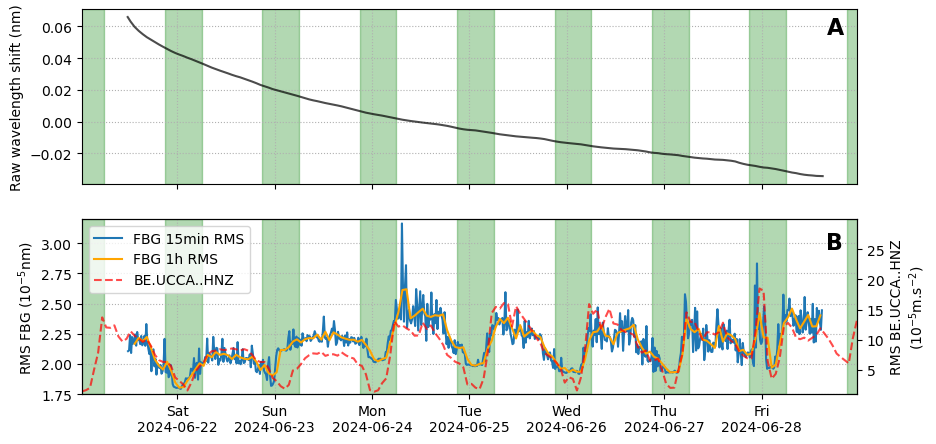

In [14]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10,5), nrows=2, sharex=True)
fbgrms15, = ax[1].plot(tim15m.to_numpy()[1:-1], np.array(rms15m[1:])*1e5, alpha=1, label='FBG 15min RMS')
fbgrms1h, = ax[1].plot(tim1h.to_numpy()[2:-1], np.array(rms1h[1:])*1e5, c='orange', label='FBG 1h RMS')

ax[1].set_ylim(1.75, 3.2)

ax[1].grid(ls=':')
#ax.set_xlabel('Time')
ax[1].set_ylabel('RMS FBG (10$^{-5}$nm)')

# Change the date format and include the name of the day
date_format = mdates.DateFormatter('%a\n%Y-%m-%d')
ax[1].xaxis.set_major_formatter(date_format)
#fig.autofmt_xdate()

for i in range(-1,8):
    sttime = np.datetime64('2024-06-21T21:00:00') + np.timedelta64(i,'D')
    endtime = np.datetime64('2024-06-22T06:00:00') + np.timedelta64(i,'D')
    ax[0].axvspan(sttime, endtime, color='g', alpha=0.3)
    ax[1].axvspan(sttime, endtime, color='g', alpha=0.3)
axb = ax[1].twinx()
pltucc, = axb.plot(time_ucc, ucc_rms1h, c='red', alpha=.7,ls='--', label=st[0].id)
axb.set_ylabel('RMS %s\n(10$^{-5}$m.s$^{-2}$)' %st[0].id)
axb.set_ylim(1e-5, 30e-5)
axb.set_yticks(np.arange(5e-5,30e-5,5e-5), np.arange(5,30,5))
ax[1].legend(handles=[fbgrms15,fbgrms1h,pltucc], loc='upper left')
ax[1].set_xlim(time_ucc[0], time_ucc[-1])

da = xr.DataArray(Twav, dims=['index'], coords={'time': dataset.index})
ax[0].plot(da.time.resample(time='1h').mean(), da.resample(time='1h').mean(), label='FBG', c='black', alpha=.7)
#ax[1].plot(da.time.resample(time='1h').mean(), detrend(da.resample(time='1h').mean()), label='FBG', c='black', ls='--', alpha=.7)
ax[0].set_ylabel('Raw wavelength shift (nm)')
ax[0].grid(ls=':')

ax[0].text(np.datetime64('2024-06-28T16'), 0.055, 'A', fontsize=16, fontweight='bold')
axb.text(np.datetime64('2024-06-28T16'), 25e-5, 'B', fontsize=16, fontweight='bold')

plt.savefig('../plots/rms_acc_rob.jpeg', dpi=300, bbox_inches='tight', transparent=True)

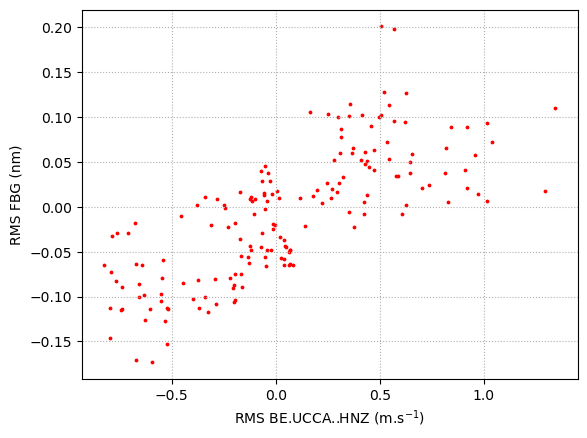

In [15]:
plt.scatter((ucc_rms1h[13:-9]-np.median(ucc_rms1h[13:-9]))/np.median(ucc_rms1h[13:-9]), (rms1h[1:]-np.median(rms1h[1:]))/np.median(rms1h[1:]), c='r',s=3)
plt.xlabel('RMS %s (m.s$^{-1}$)' %st[0].id)
plt.ylabel('RMS FBG (nm)')
plt.grid(ls=':')
#plt.savefig('./rms_acc_rob_scatter.png', dpi=300, bbox_inches='tight')

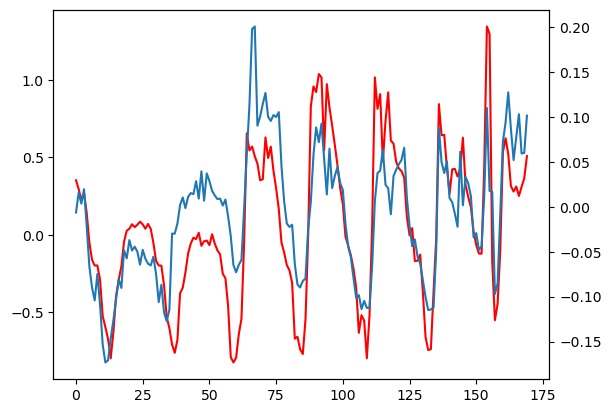

In [16]:
fig, ax = plt.subplots()
ax.plot((ucc_rms1h[13:-9]-np.median(ucc_rms1h[13:-9]))/np.median(ucc_rms1h[13:-9]), c='r')
axb = ax.twinx()
plt.plot((rms1h[1:]-np.median(rms1h[1:]))/np.median(rms1h[1:]))

In [17]:
st[0].stats

               network: BE
               station: UCCA
              location: 
               channel: HNZ
             starttime: 2024-06-28T23:00:00.000000Z
               endtime: 2024-06-29T00:00:00.000000Z
         sampling_rate: 200.0
                 delta: 0.005
                  npts: 720001
                 calib: 1.0
_fdsnws_dataselect_url: http://www.orfeus-eu.org/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'D', 'number_of_records': 1873, 'encoding': 'STEIM1', 'byteorder': '>', 'record_length': 512, 'filesize': 958976})
            processing: ['ObsPy 1.4.0: trim(endtime=UTCDateTime(2024, 6, 29, 0, 0)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2024, 6, 28, 23, 0))', "ObsPy 1.4.0: remove_response(fig=None::inventory=None::output='ACC'::plot=False::pre_filt=None::taper=True::taper_fraction=0.05::water_level=60::zero_mean=True)", "ObsPy 1.4.0: filter(options={'freqmin': 1, 'freqmax': 

## Cross-correlation of UCC and FBG

In [ ]:
plt.plot(wav[500*60*15:500*60*30])

In [ ]:
dec = decimate(wav[500*60*5:500*60*10], 5)

In [ ]:
stttime = dataset.index.to_numpy()[500*60*5]
endtime = dataset.index.to_numpy()[500*60*10]
time_ucc.append(stttime+np.timedelta64(30,'m'))
stt = obspy.UTCDateTime(stttime.astype(str))
stp = obspy.UTCDateTime(endtime.astype(str))
st = client.get_waveforms('BE', 'UCC', '--', 'HHZ', stt, stp, attach_response=True)

In [ ]:
st[0].data.shape

In [ ]:
corr = correlate(dec, st[0].data, mode='full', method='direct')
lags = correlation_lags(len(dec), len(st[0].data))

In [ ]:
plt.plot(lags/250, corr)
#plt.xlim(-20,20)